# Predicting Purchase Conversion in an E-commerce Platform

**Predictive Analytics with Machine Learning**  
**Student:** Juan Marcos Rodelgo Villanueva

This notebook develops a complete predictive analytics workflow to predict whether an e-commerce website session ends in a purchase.

In [12]:
# Basic data manipulation
from pathlib import Path
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 1234
np.random.seed(RANDOM_STATE)

## 1. Business understanding

The business objective is to predict whether a website session in an e-commerce platform will end in a purchase.

The model is designed to support the marketing team in prioritizing sessions and deciding which customers should receive actions such as checkout reminders, product recommendations, discounts or free shipping incentives.

The prediction problem is a binary classification task:

- `purchase = 1`: the session ended in a purchase.
- `purchase = 0`: the session did not end in a purchase.

The row level is **one website session**, because the business decision is made at session level. All predictors are assumed to be available before the final purchase outcome is known.

## 2. Synthetic data creation

The raw datasets used in this project were created with AI assistance specifically for this assignment. They are not taken from the internet and do not represent real customers.

The synthetic data was designed to imitate a realistic e-commerce environment with separate source tables for customers, sessions, marketing exposure and purchase outcome.

## 3. Raw data description

The project starts from four raw CSV files:

- `customers.csv`: customer profile and historical purchase information.
- `sessions.csv`: website browsing behavior for each session.
- `marketing.csv`: marketing exposure during the session.
- `orders_target.csv`: final purchase outcome for each session.

In [13]:
# Read raw synthetic datasets
# The notebook first looks for a raw_data folder. If it is not available, it reads from the current folder.

DATA_DIR = Path("../3_Raw_Data")
if not DATA_DIR.exists():
    DATA_DIR = Path(".")

customers = pd.read_csv(DATA_DIR / "customers.csv")
sessions = pd.read_csv(DATA_DIR / "sessions.csv")
marketing = pd.read_csv(DATA_DIR / "marketing.csv")
orders_target = pd.read_csv(DATA_DIR / "orders_target.csv")

raw_tables = {
    "customers": customers,
    "sessions": sessions,
    "marketing": marketing,
    "orders_target": orders_target
}

raw_summary = pd.DataFrame({
    "table": list(raw_tables.keys()),
    "rows": [table.shape[0] for table in raw_tables.values()],
    "columns": [table.shape[1] for table in raw_tables.values()]
})

raw_summary

,table,rows,columns
0,customers,1200,8
1,sessions,2520,11
2,marketing,2500,6
3,orders_target,2500,2


In [14]:
# Preview of the raw tables

for name, table in raw_tables.items():
    print()
    print(name.upper())
    display(table.head(3))


CUSTOMERS


,customer_id,age,gender,region,loyalty_member,previous_purchases,avg_previous_order_value,days_since_last_purchase
0,C00001,42.0,Male,Central,0,1,37.75,111.0
1,C00002,22.0,Male,West,0,2,48.64,56.0
2,C00003,53.0,Female,East,0,4,53.95,102.0



SESSIONS


,session_id,customer_id,device_type,traffic_source,pages_viewed,time_on_site_min,product_views,cart_items,used_search,weekend_visit,cart_value
0,S00001,C00223,Mobile,Organic,4,18.06,3,0,0,0,0.00
1,S00002,C01006,Mobile,Social,8,6.12,5,5,1,1,100.52
2,S00003,C00528,Mobile,Email,3,20.25,4,1,1,0,115.23



MARKETING


,session_id,discount_offered,email_campaign,free_shipping_banner,retargeting_click,discount_rate
0,S00001,0,0,0,0,0
1,S00002,1,0,1,0,5
2,S00003,1,1,0,0,5



ORDERS_TARGET


,session_id,purchase
0,S00001,0
1,S00002,1
2,S00003,1


## 4. Data audit and cleaning

Before building the Analytics Base Table, I check the raw data for missing values and duplicated identifiers. Duplicated session records are removed because the final row level must be one row per website session.

In [15]:
# Missing values in the raw tables

missing_summary = pd.concat(
    {name: table.isna().sum() for name, table in raw_tables.items()},
    axis=1
).fillna("")

missing_summary

,customers,sessions,marketing,orders_target
customer_id,0.0,0.0,,
age,35.0,,,
gender,0.0,,,
region,0.0,,,
loyalty_member,0.0,,,
previous_purchases,0.0,,,
avg_previous_order_value,45.0,,,
days_since_last_purchase,0.0,,,
session_id,,0.0,0.0,0.0
device_type,,0.0,,


In [16]:
# Duplicate checks using the main identifiers

duplicate_summary = pd.DataFrame({
    "table": ["customers", "sessions", "marketing", "orders_target"],
    "identifier": ["customer_id", "session_id", "session_id", "session_id"],
    "duplicated_ids": [
        customers.duplicated(subset=["customer_id"]).sum(),
        sessions.duplicated(subset=["session_id"]).sum(),
        marketing.duplicated(subset=["session_id"]).sum(),
        orders_target.duplicated(subset=["session_id"]).sum()
    ]
})

duplicate_summary

,table,identifier,duplicated_ids
0,customers,customer_id,0
1,sessions,session_id,20
2,marketing,session_id,0
3,orders_target,session_id,0


In [17]:
# Remove duplicated session records

sessions_before = sessions.shape[0]

sessions = sessions.drop_duplicates(
    subset=["session_id"],
    keep="first"
)

sessions_after = sessions.shape[0]

pd.DataFrame({
    "step": ["before_duplicate_removal", "after_duplicate_removal"],
    "session_rows": [sessions_before, sessions_after],
    "duplicated_session_ids": [20, sessions.duplicated(subset=["session_id"]).sum()]
})

,step,session_rows,duplicated_session_ids
0,before_duplicate_removal,2520,20
1,after_duplicate_removal,2500,0


## 5. Analytics Base Table construction

The raw tables are integrated into one Analytics Base Table (ABT). The ABT has one row per website session and contains the predictors and the target variable.

Identifiers are kept at this stage for traceability, but they will be removed before modelling.

In [18]:
# Build the Analytics Base Table

abt = (
    sessions
    .merge(customers, on="customer_id", how="left")
    .merge(marketing, on="session_id", how="left")
    .merge(orders_target, on="session_id", how="left")
)

print("ABT shape after integration:", abt.shape)
print("Duplicated session_id values in ABT:", abt.duplicated(subset=["session_id"]).sum())

abt.head()

ABT shape after integration: (2500, 24)
Duplicated session_id values in ABT: 0


,session_id,customer_id,device_type,traffic_source,pages_viewed,time_on_site_min,product_views,cart_items,used_search,weekend_visit,...,loyalty_member,previous_purchases,avg_previous_order_value,days_since_last_purchase,discount_offered,email_campaign,free_shipping_banner,retargeting_click,discount_rate,purchase
0,S00001,C00223,Mobile,Organic,4,18.06,3,0,0,0,...,1,1,22.75,86.0,0,0,0,0,0,0
1,S00002,C01006,Mobile,Social,8,6.12,5,5,1,1,...,1,4,102.12,30.0,1,0,1,0,5,1
2,S00003,C00528,Mobile,Email,3,20.25,4,1,1,0,...,0,0,0.00,122.0,1,1,0,0,5,1
3,S00004,C00417,Mobile,Organic,4,5.74,2,1,0,0,...,1,8,47.05,8.0,0,1,0,0,0,1
4,S00005,C00526,Desktop,Email,7,2.69,5,3,0,0,...,0,3,52.33,62.0,1,0,1,1,5,1


In [19]:
# Missing value treatment

missing_before = abt.isna().sum()

abt["age"] = abt["age"].fillna(abt["age"].median())
abt["avg_previous_order_value"] = abt["avg_previous_order_value"].fillna(
    abt["avg_previous_order_value"].median()
)
abt["time_on_site_min"] = abt["time_on_site_min"].fillna(
    abt["time_on_site_min"].median()
)
abt["traffic_source"] = abt["traffic_source"].fillna("Unknown")

missing_after = abt.isna().sum()

missing_treatment_summary = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": missing_after
})

missing_treatment_summary[missing_treatment_summary["missing_before"] > 0]

,missing_before,missing_after
traffic_source,40,0
time_on_site_min,30,0
age,81,0
avg_previous_order_value,101,0


In [20]:
# Outlier treatment using 99th percentile capping

outlier_columns = ["cart_value", "time_on_site_min"]
outlier_summary = []

for column in outlier_columns:
    p99 = abt[column].quantile(0.99)
    max_before = abt[column].max()
    values_capped = (abt[column] > p99).sum()
    
    abt[column] = np.where(abt[column] > p99, p99, abt[column])
    
    outlier_summary.append({
        "variable": column,
        "p99_cap": round(p99, 2),
        "max_before": round(max_before, 2),
        "max_after": round(abt[column].max(), 2),
        "values_capped": int(values_capped)
    })

pd.DataFrame(outlier_summary)

,variable,p99_cap,max_before,max_after,values_capped
0,cart_value,463.89,2622.00,463.89,25
1,time_on_site_min,24.71,193.26,24.71,25


In [21]:
# Final ABT quality check

abt_quality = pd.DataFrame({
    "check": ["rows", "columns", "duplicated_session_ids", "total_missing_values"],
    "value": [
        abt.shape[0],
        abt.shape[1],
        abt.duplicated(subset=["session_id"]).sum(),
        abt.isna().sum().sum()
    ]
})

target_distribution = abt["purchase"].value_counts(normalize=True).sort_index().round(3)

print("Target distribution:")
display(target_distribution)

abt_quality

Target distribution:


purchase
0    0.635
1    0.365
Name: proportion, dtype: float64

,check,value
0,rows,2500
1,columns,24
2,duplicated_session_ids,0
3,total_missing_values,0


In [22]:
# Save clean ABT

abt.to_csv("final_abt_clean.csv", index=False)

## 6. Exploratory Data Analysis

The EDA checks whether the target and the main predictors follow reasonable business patterns before model estimation.

,count,percentage
purchase,,
0,1588,0.635
1,912,0.365


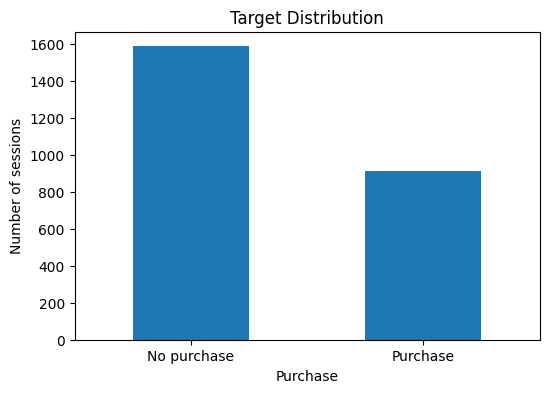

In [23]:
# Target distribution

target_table = pd.DataFrame({
    "count": abt["purchase"].value_counts().sort_index(),
    "percentage": abt["purchase"].value_counts(normalize=True).sort_index().round(3)
})

display(target_table)

plt.figure(figsize=(6, 4))
target_table["count"].plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Purchase")
plt.ylabel("Number of sessions")
plt.xticks(ticks=[0, 1], labels=["No purchase", "Purchase"], rotation=0)
plt.show()

,count,mean
cart_items,,
0,1246,0.220
1,606,0.378
2,299,0.532
3,199,0.663
4,108,0.769
5,42,0.833


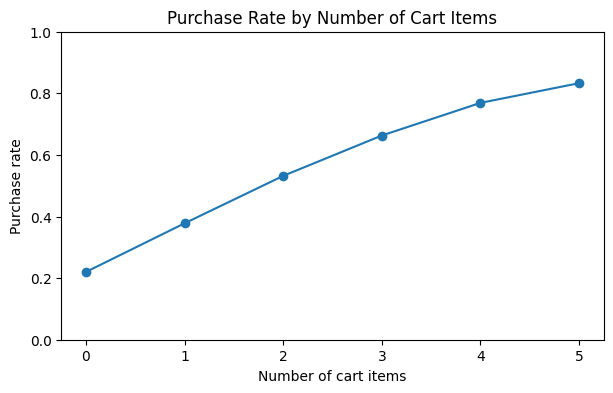

In [24]:
# Purchase rate by cart activity

purchase_by_cart = abt.groupby("cart_items")["purchase"].agg(["count", "mean"])
purchase_by_cart["mean"] = purchase_by_cart["mean"].round(3)

display(purchase_by_cart)

plt.figure(figsize=(7, 4))
plt.plot(purchase_by_cart.index, purchase_by_cart["mean"], marker="o")
plt.title("Purchase Rate by Number of Cart Items")
plt.xlabel("Number of cart items")
plt.ylabel("Purchase rate")
plt.ylim(0, 1)
plt.show()

In [25]:
# Purchase rate by traffic source

purchase_by_source = (
    abt.groupby("traffic_source")["purchase"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)
purchase_by_source["mean"] = purchase_by_source["mean"].round(3)

purchase_by_source

,count,mean
traffic_source,,
Unknown,40,0.500
Email,464,0.425
Direct,334,0.368
Organic,714,0.352
Paid Ads,599,0.344
Social,349,0.330


In [26]:
# Purchase rate by marketing actions

marketing_variables = [
    "discount_offered",
    "free_shipping_banner",
    "email_campaign",
    "retargeting_click"
]

marketing_effects = []

for variable in marketing_variables:
    rates = abt.groupby(variable)["purchase"].mean()
    marketing_effects.append({
        "variable": variable,
        "purchase_rate_when_0": round(rates.loc[0], 3),
        "purchase_rate_when_1": round(rates.loc[1], 3),
        "difference": round(rates.loc[1] - rates.loc[0], 3)
    })

pd.DataFrame(marketing_effects).sort_values("difference", ascending=False)

,variable,purchase_rate_when_0,purchase_rate_when_1,difference
3,retargeting_click,0.349,0.447,0.098
0,discount_offered,0.345,0.413,0.068
2,email_campaign,0.353,0.406,0.054
1,free_shipping_banner,0.345,0.395,0.050


In [27]:
# Numerical predictors by purchase outcome

numerical_variables = [
    "pages_viewed",
    "time_on_site_min",
    "product_views",
    "cart_items",
    "cart_value",
    "previous_purchases",
    "days_since_last_purchase"
]

abt.groupby("purchase")[numerical_variables].mean().round(2)

,pages_viewed,time_on_site_min,product_views,cart_items,cart_value,previous_purchases,days_since_last_purchase
purchase,,,,,,,
0,5.82,7.16,3.1,0.63,36.75,2.91,87.5
1,6.19,8.14,3.3,1.59,83.10,3.21,67.9


## 7. Model preparation

Before modelling, identifiers are removed, categorical variables are encoded, the target is separated from the predictors and a stratified train/test split is created.

In [28]:
# Remove identifiers and encode categorical variables

model_data = abt.drop(columns=["session_id", "customer_id"])

categorical_columns = ["device_type", "traffic_source", "gender", "region"]

model_data_encoded = pd.get_dummies(
    model_data,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

y = model_data_encoded["purchase"].astype(int)
X = model_data_encoded.drop(columns=["purchase"])

print("Predictors shape:", X.shape)
print("Target shape:", y.shape)

Predictors shape: (2500, 30)
Target shape: (2500,)


In [29]:
# Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

split_summary = pd.DataFrame({
    "sample": ["train", "test"],
    "rows": [X_train.shape[0], X_test.shape[0]],
    "purchase_rate": [y_train.mean().round(3), y_test.mean().round(3)]
})

split_summary

,sample,rows,purchase_rate
0,train,1750,0.365
1,test,750,0.365


In [30]:
# Scaling for models that are sensitive to variable scale

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 8. Model estimation

Four supervised classification models are estimated: Logistic Regression, Decision Tree, Random Forest and KNN.

Logistic Regression and KNN use scaled predictors. Tree-based models use the original predictors.

In [31]:
# Define and train models

models = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
        "uses_scaled_data": True
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
        "X_train": X_train,
        "X_test": X_test,
        "uses_scaled_data": False
    },
    "Random Forest": {
        "model": RandomForestClassifier(
            n_estimators=100,
            max_depth=6,
            random_state=RANDOM_STATE
        ),
        "X_train": X_train,
        "X_test": X_test,
        "uses_scaled_data": False
    },
    "KNN": {
        "model": KNeighborsClassifier(n_neighbors=15),
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
        "uses_scaled_data": True
    }
}

for model_name, model_info in models.items():
    model_info["model"].fit(model_info["X_train"], y_train)
    print(f"{model_name} trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
KNN trained


## 9. Model evaluation and selection

The models are evaluated on the test sample using accuracy, precision, recall, F1-score and ROC AUC. ROC AUC is especially relevant because the final business use is based on ranking sessions by predicted purchase probability.

In [32]:
# Generate predictions and evaluate all models

evaluation_results = []

for model_name, model_info in models.items():
    model = model_info["model"]
    X_test_model = model_info["X_test"]
    
    y_pred = model.predict(X_test_model)
    y_prob = model.predict_proba(X_test_model)[:, 1]
    
    model_info["y_pred"] = y_pred
    model_info["y_prob"] = y_prob
    
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

evaluation_table = (
    pd.DataFrame(evaluation_results)
    .sort_values("ROC AUC", ascending=False)
    .reset_index(drop=True)
)

evaluation_table.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC AUC
0,Logistic Regression,0.740,0.716,0.478,0.573,0.777
1,Random Forest,0.723,0.717,0.398,0.512,0.750
2,Decision Tree,0.703,0.618,0.489,0.546,0.708
3,KNN,0.687,0.682,0.266,0.383,0.664


In [33]:
# Select final model based on ROC AUC

best_model_name = evaluation_table.loc[0, "Model"]
final_model_info = models[best_model_name]
final_model = final_model_info["model"]
final_model_uses_scaled_data = final_model_info["uses_scaled_data"]
final_y_pred = final_model_info["y_pred"]
final_y_prob = final_model_info["y_prob"]

print("Selected final model:", best_model_name)
display(evaluation_table[evaluation_table["Model"] == best_model_name].round(3))

Selected final model: Logistic Regression


,Model,Accuracy,Precision,Recall,F1-score,ROC AUC
0,Logistic Regression,0.74,0.716,0.478,0.573,0.777


In [34]:
# Confusion matrix of the selected model

cm = confusion_matrix(y_test, final_y_pred)

confusion_matrix_table = pd.DataFrame(
    cm,
    index=["Actual No Purchase", "Actual Purchase"],
    columns=["Predicted No Purchase", "Predicted Purchase"]
)

confusion_matrix_table

,Predicted No Purchase,Predicted Purchase
Actual No Purchase,424,52
Actual Purchase,143,131


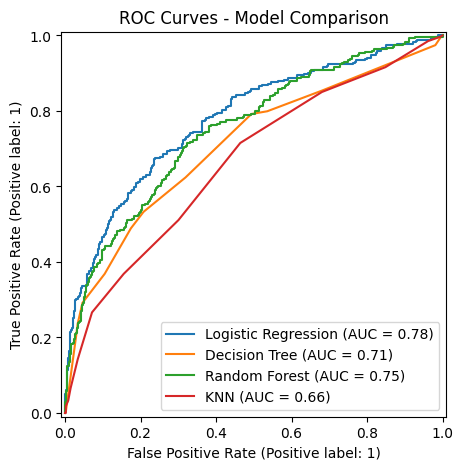

In [35]:
# ROC curves

plt.figure(figsize=(7, 5))
ax = plt.gca()

for model_name, model_info in models.items():
    RocCurveDisplay.from_predictions(
        y_test,
        model_info["y_prob"],
        name=model_name,
        ax=ax
    )

plt.title("ROC Curves - Model Comparison")
plt.show()

In [36]:
# Interpretation of the selected model

if best_model_name in ["Decision Tree", "Random Forest"]:
    feature_importance = pd.DataFrame({
        "feature": X.columns,
        "importance": final_model.feature_importances_
    }).sort_values("importance", ascending=False)
    
    display(feature_importance.head(10))

elif best_model_name == "Logistic Regression":
    feature_importance = pd.DataFrame({
        "feature": X.columns,
        "coefficient": final_model.coef_[0],
        "absolute_coefficient": abs(final_model.coef_[0])
    }).sort_values("absolute_coefficient", ascending=False)
    
    display(feature_importance.head(10))

else:
    print("The selected KNN model does not provide direct feature importance.")

,feature,coefficient,absolute_coefficient
3,cart_items,1.051809,1.051809
11,days_since_last_purchase,-0.315439,0.315439
9,previous_purchases,0.228056,0.228056
6,cart_value,-0.218272,0.218272
1,time_on_site_min,0.199739,0.199739
8,loyalty_member,0.194832,0.194832
12,discount_offered,0.185410,0.185410
15,retargeting_click,0.178349,0.178349
19,traffic_source_Email,0.149333,0.149333
0,pages_viewed,0.135958,0.135958


## 10. Final scoring process

The selected model is applied to a scoring sample where the target variable is not used. For demonstration purposes, the scoring sample is created by selecting existing sessions and removing `purchase`, simulating new sessions with unknown outcome.

In [37]:
# Create scoring sample

scoring_raw = (
    abt
    .sample(n=20, random_state=RANDOM_STATE)
    .drop(columns=["purchase"])
    .copy()
)

scoring_ids = scoring_raw[["session_id", "customer_id"]].copy()
scoring_model_data = scoring_raw.drop(columns=["session_id", "customer_id"])

# Apply same categorical encoding and align columns with training predictors
scoring_model_encoded = pd.get_dummies(
    scoring_model_data,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

scoring_model_encoded = scoring_model_encoded.reindex(columns=X.columns, fill_value=0)

if final_model_uses_scaled_data:
    X_score_for_model = scaler.transform(scoring_model_encoded)
else:
    X_score_for_model = scoring_model_encoded

print("Scoring data shape:", scoring_model_encoded.shape)

Scoring data shape: (20, 30)


In [38]:
# Generate scoring results

scoring_probabilities = final_model.predict_proba(X_score_for_model)[:, 1]
scoring_predictions = (scoring_probabilities >= 0.5).astype(int)

scoring_results = scoring_ids.copy()
scoring_results["purchase_probability"] = scoring_probabilities.round(3)
scoring_results["predicted_purchase"] = scoring_predictions


def assign_priority(probability):
    if probability >= 0.70:
        return "High priority"
    elif probability >= 0.40:
        return "Medium priority"
    else:
        return "Low priority"


def recommend_action(priority):
    if priority == "High priority":
        return "Checkout reminder or product recommendation"
    elif priority == "Medium priority":
        return "Discount or free shipping incentive"
    else:
        return "No immediate paid marketing action"


scoring_results["marketing_priority"] = scoring_results["purchase_probability"].apply(assign_priority)
scoring_results["recommended_action"] = scoring_results["marketing_priority"].apply(recommend_action)

scoring_results = scoring_results.sort_values(
    "purchase_probability",
    ascending=False
).reset_index(drop=True)

scoring_results.to_csv("final_scoring_results.csv", index=False)

scoring_results

,session_id,customer_id,purchase_probability,predicted_purchase,marketing_priority,recommended_action
0,S01215,C00735,0.798,1,High priority,Checkout reminder or product recommendation
1,S01625,C01027,0.752,1,High priority,Checkout reminder or product recommendation
2,S01593,C00148,0.715,1,High priority,Checkout reminder or product recommendation
3,S02165,C01057,0.599,1,Medium priority,Discount or free shipping incentive
4,S01206,C00490,0.512,1,Medium priority,Discount or free shipping incentive
5,S02404,C00607,0.374,0,Low priority,No immediate paid marketing action
6,S02307,C00698,0.374,0,Low priority,No immediate paid marketing action
7,S01134,C00579,0.366,0,Low priority,No immediate paid marketing action
8,S02250,C00853,0.356,0,Low priority,No immediate paid marketing action
9,S00904,C00803,0.356,0,Low priority,No immediate paid marketing action


In [39]:
# Summary of scored sessions by priority level

priority_summary = scoring_results.groupby("marketing_priority").agg(
    number_of_sessions=("session_id", "count"),
    average_purchase_probability=("purchase_probability", "mean")
).round(3)

priority_summary

,number_of_sessions,average_purchase_probability
marketing_priority,,
High priority,3,0.755
Low priority,15,0.255
Medium priority,2,0.556


## 11. Conclusions and limitations

This project develops a complete predictive analytics workflow from raw synthetic data to final scoring.

The final model is selected using ROC AUC because the business objective is based on ranking sessions by purchase probability. The scoring process converts model probabilities into marketing priority levels and recommended actions.

The main limitation is that the dataset is synthetic. In a real business context, the model should be validated with real data, the marketing thresholds should be optimized using costs and expected profit, and model performance should be monitored over time.

In [40]:
# Final project summary

final_project_summary = pd.DataFrame({
    "item": [
        "ABT rows",
        "ABT columns",
        "Selected model",
        "Selected model ROC AUC",
        "Scored sessions"
    ],
    "value": [
        abt.shape[0],
        abt.shape[1],
        best_model_name,
        round(evaluation_table.loc[0, "ROC AUC"], 3),
        scoring_results.shape[0]
    ]
})

final_project_summary

,item,value
0,ABT rows,2500
1,ABT columns,24
2,Selected model,Logistic Regression
3,Selected model ROC AUC,0.777
4,Scored sessions,20
